# COMP 6011 — Individual Project 2.2: COCO Image–Caption Retrieval

**Contributor:** Pranav Kadari (Member 3)

**Implementation notebook (individual experimental work).** The shared feature archive contains precomputed ResNet-50 image features and BERT text features. This notebook independently trains and evaluates **InfoNCE**, **triplet ranking**, and **early-fusion pair classification** on identical image-disjoint train/validation/test splits.


## 1 — Setup and reproducibility

In [1]:
import os, random, json, zipfile, time, platform, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__, '| Device:', DEVICE)
print('Platform:', platform.platform())

Python: 3.13.18 | PyTorch: 2.11.0+cpu | Device: cpu
Platform: Linux-6.6.159+-x86_64-with-glibc2.39


In [2]:
# Supports standard Jupyter, Colab, and mounted /mnt/data environments.
candidates = [Path('multimodal_shared_data(1).zip'), Path('multimodal_shared_data.zip'),
              Path('/content/multimodal_shared_data(1).zip'), Path('/content/multimodal_shared_data.zip'),
              Path('/mnt/data/multimodal_shared_data(1).zip')]
archive = next((p for p in candidates if p.is_file()), None)
if archive is None:
    try:
        from google.colab import files
        print('Upload the shared feature ZIP:')
        uploaded = files.upload()
        archive = next((Path(k) for k in uploaded if k.endswith('.zip')), None)
    except ImportError:
        pass
if archive is None: raise FileNotFoundError('Upload multimodal_shared_data(1).zip beside notebook.')
OUT = Path('individual_coco_results'); OUT.mkdir(exist_ok=True)
ROOT = archive.parent / 'individual_coco_extracted'
if not (ROOT/'shared_data'/'coco_splits.json').exists():
    with zipfile.ZipFile(archive) as z: z.extractall(ROOT)
print('Archive:', archive, '| Extracted:', ROOT)

Archive: multimodal_shared_data.zip | Extracted: individual_coco_extracted


## 2 — Data quality audit, alignment and preprocessing

The archive provides 5,000 image embeddings in the same order as the concatenated split manifest, plus a `caption_image_indices` array identifying the correct image for each caption. We **verify these assumptions** below rather than assuming that the text and image arrays have matching row positions. No feature fitting or hyperparameter selection uses the test split.

In [3]:
with open(ROOT/'shared_data'/'coco_splits.json', encoding='utf-8') as f:
    splits = json.load(f)
with open(ROOT/'results'/'dataset_audit.json', encoding='utf-8') as f:
    audit = json.load(f)
image_data = torch.load(ROOT/'shared_data'/'image_features.pt', map_location='cpu', weights_only=True)
text_data = torch.load(ROOT/'shared_data'/'text_features.pt', map_location='cpu', weights_only=True)
image_raw = image_data['features'].float()
text_raw = text_data['features'].float()
image_ids = image_data['image_ids']
caption_to_image = np.asarray(text_data['caption_image_indices'], dtype=np.int64)
captions = text_data['captions']
caption_splits = text_data['caption_splits']
records = [r for split in ('train','validation','test') for r in splits[split]]
expected_ids = [r['id'] for r in records]
assert len(image_ids) == len(records) == image_raw.shape[0]
assert [str(i) for i in image_ids] == [str(i) for i in expected_ids], 'Image IDs/order do not match manifest.'
assert len(captions) == text_raw.shape[0] == len(caption_to_image) == len(caption_splits)
assert caption_to_image.min() >= 0 and caption_to_image.max() < len(records)
assert torch.isfinite(image_raw).all() and torch.isfinite(text_raw).all()
image_split = np.asarray([s for s in ('train','validation','test') for _ in splits[s]])
caption_splits = np.asarray(caption_splits)
assert np.all(image_split[caption_to_image] == caption_splits), 'Caption-to-image split mismatch.'
image_ix = {s:np.flatnonzero(image_split==s) for s in ('train','validation','test')}
cap_ix = {s:np.flatnonzero(caption_splits==s) for s in ('train','validation','test')}
assert len(set(map(str, np.array(image_ids)[image_ix['train']] )) & set(map(str, np.array(image_ids)[image_ix['test']]))) == 0
print('Image encoder:', image_data['encoder'], '| Text encoder:', text_data['encoder'])
print('Feature dimensions:', tuple(image_raw.shape), tuple(text_raw.shape))
print(pd.DataFrame([{'split':s,'images':len(image_ix[s]),'captions':len(cap_ix[s])} for s in image_ix]).to_string(index=False))
print('Null/NaN check: PASSED | Split/pair alignment: PASSED')

Image encoder: ResNet50_Weights.DEFAULT | Text encoder: bert-base-uncased
Feature dimensions: (5000, 2048) (25010, 768)
     split  images  captions
     train    4000     20008
validation     500      2499
      test     500      2503
Null/NaN check: PASSED | Split/pair alignment: PASSED


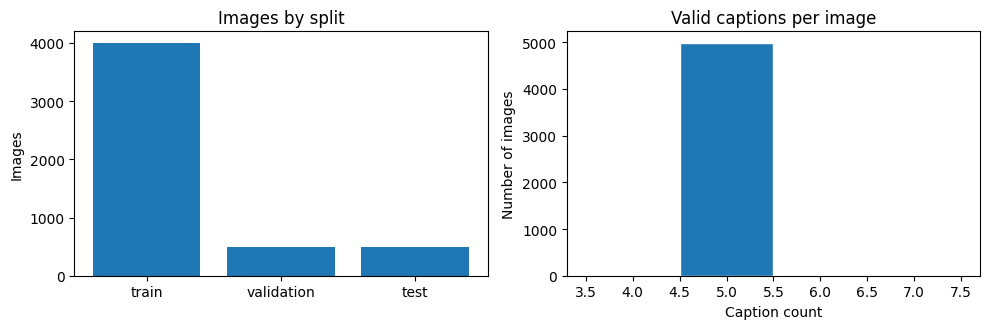

Counts: {'count': 5000.0, 'mean': 5.002, 'std': 0.06322024485773606, 'min': 4.0, '25%': 5.0, '50%': 5.0, '75%': 5.0, 'max': 7.0}


In [4]:
# Illustrative data-quality figure (split size and caption counts per image)
counts = np.bincount(caption_to_image, minlength=len(image_ids))
fig, ax = plt.subplots(1,2,figsize=(10,3.4))
ax[0].bar(list(image_ix),[len(image_ix[s]) for s in image_ix]); ax[0].set(title='Images by split',ylabel='Images')
ax[1].hist(counts, bins=np.arange(counts.min()-.5, counts.max()+1.5,1),edgecolor='white')
ax[1].set(title='Valid captions per image',xlabel='Caption count',ylabel='Number of images')
plt.tight_layout(); plt.savefig(OUT/'data_quality.png',dpi=160); plt.show()
print('Counts:',pd.Series(counts).describe().to_dict())

### Feature transformation

We L2-normalise each **precomputed** vector for stable cosine comparisons and project each modality into the same trainable 256-dimensional latent space. Since the encoders are pretrained, this experiment does not fine-tune the original image or text backbones. This reduces compute but limits domain adaptation.

In [5]:
Ximg = F.normalize(image_raw, dim=1)
Xtxt = F.normalize(text_raw, dim=1)
# For paired mini-batches, select one caption from each image per epoch, preventing other valid captions becoming false negatives.
image_to_caps = [[] for _ in range(len(image_ids))]
for c,idx in enumerate(caption_to_image): image_to_caps[int(idx)].append(c)
assert all(image_to_caps[i] for i in range(len(image_ids)))

class PairBatchDataset(Dataset):
    def __init__(self, image_indices, seed=42):
        self.image_indices = np.array(image_indices, dtype=int)
        self.rng = np.random.default_rng(seed)
        self.refresh()
    def refresh(self):
        self.chosen_caps = {int(i):int(self.rng.choice(image_to_caps[int(i)])) for i in self.image_indices}
    def __len__(self): return len(self.image_indices)
    def __getitem__(self, j):
        i=int(self.image_indices[j]); c=self.chosen_caps[i]
        return Ximg[i], Xtxt[c]

TRAIN_BATCH=128
train_pairs=PairBatchDataset(image_ix['train'])
train_loader=DataLoader(train_pairs,batch_size=TRAIN_BATCH,shuffle=True,num_workers=0,drop_last=False)
print('Pair sampler:',len(train_pairs),'distinct images per epoch')

Pair sampler: 4000 distinct images per epoch


## 3 — Method A: symmetric InfoNCE contrastive learning

Train two projection MLPs with a symmetric cross-entropy objective on the image-to-text and text-to-image similarity matrix. Each mini-batch contains **different image IDs**, so other captions of the same image are not incorrectly designated as negatives. Citation: Radford et al. (2021); van den Oord et al. (2018).

In [6]:
class DualEncoder(nn.Module):
    def __init__(self, dim=256, dropout=.10):
        super().__init__()
        def head(n): return nn.Sequential(nn.Linear(n,512),nn.ReLU(),nn.Dropout(dropout),nn.Linear(512,dim))
        self.img=head(Ximg.shape[1]); self.txt=head(Xtxt.shape[1])
    def encode_image(self,x): return F.normalize(self.img(x),dim=-1)
    def encode_text(self,x): return F.normalize(self.txt(x),dim=-1)

def contrastive_loss(z_i,z_t,temperature=.07):
    logits=z_i@z_t.T/temperature
    targets=torch.arange(len(z_i),device=z_i.device)
    return (F.cross_entropy(logits,targets)+F.cross_entropy(logits.T,targets))/2

def train_dual(model, method, epochs=8, lr=8e-4, patience=None):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    history = []
    best, best_state, best_epoch = -1.0, None, 0
    t0 = time.perf_counter()
    for epoch in range(epochs):
        train_pairs.refresh()
        model.train()
        losses = []
        for xi, xt in train_loader:
            xi, xt = xi.to(DEVICE), xt.to(DEVICE)
            zi, zt = model.encode_image(xi), model.encode_text(xt)
            if method == 'infonce':
                loss = contrastive_loss(zi, zt)
            else:
                loss = triplet_ranking_loss(zi, zt)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 2.0)
            opt.step()
            losses.append(float(loss.detach().cpu()))
        model.eval()
        val_scores = dual_scores(model, 'validation')
        metrics = compute_metrics(val_scores, 'validation')
        val_i2t, val_t2i = metrics['i2t_R@1'], metrics['t2i_R@1']
        # Aggregate both retrieval directions for model selection, validation only.
        selection_score = (val_i2t + val_t2i) / 2
        history.append({'epoch': epoch + 1, 'train_loss': np.mean(losses),
                        'val_i2t_R@1': val_i2t, 'val_t2i_R@1': val_t2i,
                        'val_mean_R@1': selection_score})
        print(method, 'epoch', epoch + 1, 'loss', round(np.mean(losses), 4),
              'val i2t R@1', round(val_i2t, 4), 'val t2i R@1', round(val_t2i, 4))
        if selection_score > best + 1e-6:
            best, best_epoch = selection_score, epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if patience is not None and epoch + 1 - best_epoch >= patience:
            print('Early stopping at epoch', epoch + 1, '; best epoch:', best_epoch)
            break
    model.load_state_dict(best_state)
    print(method, 'selected epoch', best_epoch, 'validation mean R@1', round(best, 4))
    return pd.DataFrame(history), time.perf_counter() - t0

def dual_scores(model, split):
    model.eval(); ii=image_ix[split]; cc=cap_ix[split]
    with torch.no_grad():
        # Blocks avoid memory spikes on smaller Colab GPUs.
        zi=torch.cat([model.encode_image(x.to(DEVICE)).cpu() for x in Ximg[ii].split(512)])
        zt=torch.cat([model.encode_text(x.to(DEVICE)).cpu() for x in Xtxt[cc].split(512)])
    return (zi@zt.T).numpy()

## 4 — Method B: stabilised top-k triplet ranking

The initial **single hardest-negative hinge loss** produced nearly random retrieval. We replace it with a **top-k averaged ranking loss** that combines a small set of challenging negatives and random in-batch negatives. Unlike using only the single hardest negative, this distributes gradients across several candidate mistakes. The margin, number of negatives and learning rate are hyperparameters chosen using **validation only**. There is exactly one caption per distinct image in each training batch, so off-diagonal entries are true negative pairs within that sampled batch. We use symmetric image→text and text→image ranking constraints.

We train this model for up to 24 epochs with early stopping, a lower learning rate and validation-based checkpointing. Model performance is not assumed to improve; compare held-out metrics after execution.

In [7]:
def triplet_ranking_loss(zi, zt, margin=0.2, top_k=8, random_weight=0.25):
    """Symmetric top-k triplet ranking with an in-batch random-negative term.

    Each mini-batch contains distinct images and one caption per image, so
    the diagonal is positive and all off-diagonal pairs are negatives.
    """
    scores = zi @ zt.T
    n = scores.shape[0]
    if n < 2:
        return scores.sum() * 0.0
    pos = scores.diagonal()
    eye = torch.eye(n, dtype=torch.bool, device=scores.device)
    negative_scores = scores.masked_fill(eye, -1e4)
    k = min(top_k, n - 1)
    hard_i2t = negative_scores.topk(k, dim=1).values
    hard_t2i = negative_scores.topk(k, dim=0).values.T
    # Ranking error: positive similarity should exceed negative by margin.
    loss_hard = (
        F.relu(margin + hard_i2t - pos[:, None]).mean() +
        F.relu(margin + hard_t2i - pos[:, None]).mean()
    ) / 2.0
    # All-negative term prevents optimization being driven entirely by outliers.
    violation_i2t = F.relu(margin + scores - pos[:, None]).masked_fill(eye, 0)
    violation_t2i = F.relu(margin + scores - pos[None, :]).masked_fill(eye, 0)
    loss_all = (violation_i2t.sum() + violation_t2i.sum()) / (2 * n * (n-1))
    return (1 - random_weight) * loss_hard + random_weight * loss_all

# A correct pair must rank above a mismatched pair by the margin.
_demo_i = F.normalize(torch.eye(3), dim=1)
assert triplet_ranking_loss(_demo_i, _demo_i).item() == 0.0
print('Top-k triplet loss sanity check passed.')

Top-k triplet loss sanity check passed.


## 5 — Method C: early fusion binary matching network

Concatenate `[image feature, text feature, |image - projected text|]` after trainable 256-d projections, and predict whether a pair matches. Positive pairs are balanced against randomly sampled **different-image** negatives. The network is trained using binary cross-entropy and scored over all test candidate pairs. Because this is a *pairwise* model, retrieval scoring is more expensive than dual-encoder matrix multiplication.

In [8]:
class EarlyFusion(nn.Module):
    def __init__(self, latent=256):
        super().__init__()
        self.ip=nn.Sequential(nn.Linear(Ximg.shape[1],latent),nn.ReLU())
        self.tp=nn.Sequential(nn.Linear(Xtxt.shape[1],latent),nn.ReLU())
        self.score=nn.Sequential(nn.Linear(latent*3,256),nn.ReLU(),nn.Dropout(.1),nn.Linear(256,1))
    def forward(self,xi,xt):
        a=self.ip(xi);b=self.tp(xt)
        return self.score(torch.cat([a,b,torch.abs(a-b)],dim=-1)).squeeze(-1)

def early_train_epoch(model,opt,negative_ratio=2,batch_size=256):
    model.train(); losses=[]
    # Generate negatives from training images ONLY (never leak val/test).
    imgs=np.tile(image_ix['train'],1+negative_ratio)
    pos_caps=np.array([np.random.choice(image_to_caps[int(i)]) for i in image_ix['train']],dtype=int)
    caps=np.concatenate([pos_caps] + [np.random.choice(cap_ix['train'],size=len(pos_caps)) for _ in range(negative_ratio)])
    # Match image position blockwise; resample any accidental positive negatives.
    for start in range(len(pos_caps),len(caps)):
        i=int(imgs[start]); c=int(caps[start])
        while caption_to_image[c]==i: c=int(np.random.choice(cap_ix['train']))
        caps[start]=c
    labels=np.concatenate([np.ones(len(pos_caps)),np.zeros(len(pos_caps)*negative_ratio)]).astype('float32')
    order=np.random.permutation(len(imgs))
    for piece in np.array_split(order,max(1,int(np.ceil(len(order)/batch_size)))):
        xi=Ximg[imgs[piece]].to(DEVICE);xt=Xtxt[caps[piece]].to(DEVICE)
        y=torch.tensor(labels[piece],device=DEVICE)
        logits=model(xi,xt);loss=F.binary_cross_entropy_with_logits(logits,y)
        opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),2);opt.step()
        losses.append(loss.item())
    return float(np.mean(losses))

def early_scores(model, split, block=8192):
    model.eval(); ii=image_ix[split]; cc=cap_ix[split]
    out=np.empty((len(ii),len(cc)),dtype=np.float32)
    # Cache independently projected features once, avoiding repeated large ResNet/BERT matrix multiplications.
    with torch.inference_mode():
        ai=torch.cat([model.ip(x.to(DEVICE)).cpu() for x in Ximg[ii].split(512)])
        bt=torch.cat([model.tp(x.to(DEVICE)).cpu() for x in Xtxt[cc].split(512)])
        ncap=len(cc)
        for start in range(0,len(ii)*ncap,block):
            end=min(start+block,len(ii)*ncap)
            linear=torch.arange(start,end)
            a=ai[linear//ncap].to(DEVICE); b=bt[linear%ncap].to(DEVICE)
            merged=torch.cat([a,b,torch.abs(a-b)],dim=1)
            out.reshape(-1)[start:end]=model.score(merged).squeeze(-1).cpu().numpy()
    return out

def train_early(model,epochs=8,lr=7e-4):
    model.to(DEVICE);opt=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=1e-4)
    hist=[];best=-1;state=None;t0=time.perf_counter()
    for ep in range(epochs):
        loss=early_train_epoch(model,opt)
        val=compute_metrics(early_scores(model,'validation'),'validation')['i2t_R@1']
        hist.append({'epoch':ep+1,'train_loss':loss,'val_i2t_R@1':val})
        print('early epoch',ep+1,'loss',round(loss,4),'val i2t R@1',round(val,4))
        if val>best:
            best=val;state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(state)
    return pd.DataFrame(hist),time.perf_counter()-t0

## 6 — Retrieval metrics (both directions)

Recall@K asks whether a relevant item occurs among the first K ranked results. **Image→Text** succeeds if *any* caption belonging to the query image appears in top K. **Text→Image** succeeds if the caption's exact image appears in top K. MRR averages reciprocal rank of the first relevant result. These definitions correctly accommodate multiple captions per COCO image.

In [9]:
def ranks_from_scores(scores,split):
    ii=image_ix[split];cc=cap_ix[split]
    assert scores.shape==(len(ii),len(cc))
    # Use the image's global index; captions can have many-to-one positive mapping.
    true_img_for_cap=caption_to_image[cc]
    img_ranks=[]
    for row,i in enumerate(ii):
        good=np.flatnonzero(true_img_for_cap==i)
        # How many scores are strictly above best relevant caption?
        best_good=scores[row,good].max()
        img_ranks.append(int(1+np.sum(scores[row]>best_good)))
    # One positive image per caption.
    global_to_local={int(i):j for j,i in enumerate(ii)}
    text_ranks=[]
    for c,global_image in enumerate(true_img_for_cap):
        row=global_to_local[int(global_image)]
        positive=scores[row,c]
        text_ranks.append(int(1+np.sum(scores[:,c]>positive)))
    return np.array(img_ranks),np.array(text_ranks)

def compute_metrics(scores,split):
    r_i,r_t=ranks_from_scores(scores,split)
    output={}
    for prefix,ranks in [('i2t',r_i),('t2i',r_t)]:
        for k in (1,5,10): output[f'{prefix}_R@{k}']=float(np.mean(ranks<=k))
        output[f'{prefix}_MRR']=float(np.mean(1/ranks))
    return output

# Sanity check: oracle scores assign every true caption higher than mismatches.
S=np.zeros((len(image_ix['validation']),len(cap_ix['validation'])),dtype=np.float32)
for r,i in enumerate(image_ix['validation']): S[r,caption_to_image[cap_ix['validation']]==i]=1
assert compute_metrics(S,'validation')['i2t_R@1']==1.0
assert compute_metrics(S,'validation')['t2i_R@1']==1.0
print('Retrieval metrics checked using oracle ranking.')

Retrieval metrics checked using oracle ranking.


## 7 — Independently train and compare three approaches

Each model starts from a fresh random initialisation and uses the same fixed splits. InfoNCE and Early Fusion retain the original 8-epoch settings. Triplet Ranking is a **new validation-tuned experiment**: up to 24 epochs, LR 3e-4, top-8 in-batch negatives and patience 6. Model selection for dual encoders uses the mean of image→text and text→image validation Recall@1; test performance is evaluated **once after model selection**. All learned model weights, training histories and metrics are saved to the output folder. Do not report the earlier executed model scores as results of this optimized notebook.

In [10]:
EPOCHS = 8   # Increase only after an initial end-to-end successful run; record changes in report.
models={}; histories={}; train_seconds={}; test_scores={}; score_seconds={}

def run_experiment(name,model,trainer):
    print('\n===== '+name+' =====')
    hist,seconds=trainer(model)
    histories[name]=hist;train_seconds[name]=seconds;models[name]=model
    start=time.perf_counter()
    test_scores[name]=early_scores(model,'test') if name=='Early Fusion' else dual_scores(model,'test')
    score_seconds[name]=time.perf_counter()-start
    torch.save(model.state_dict(),OUT/(name.lower().replace(' ','_')+'.pt'))
    hist.to_csv(OUT/(name.lower().replace(' ','_')+'_history.csv'),index=False)

run_experiment('InfoNCE',DualEncoder(),lambda m:train_dual(m,'infonce',epochs=EPOCHS))
run_experiment('Triplet Ranking',DualEncoder(),lambda m:train_dual(m,'triplet',epochs=24,lr=3e-4,patience=6))
run_experiment('Early Fusion',EarlyFusion(),lambda m:train_early(m,epochs=EPOCHS))


===== InfoNCE =====
infonce epoch 1 loss 3.2666 val i2t R@1 0.17 val t2i R@1 0.116
infonce epoch 2 loss 2.0391 val i2t R@1 0.25 val t2i R@1 0.1805
infonce epoch 3 loss 1.6165 val i2t R@1 0.262 val t2i R@1 0.2057
infonce epoch 4 loss 1.386 val i2t R@1 0.26 val t2i R@1 0.2209
infonce epoch 5 loss 1.2656 val i2t R@1 0.266 val t2i R@1 0.2193
infonce epoch 6 loss 1.1598 val i2t R@1 0.256 val t2i R@1 0.2201
infonce epoch 7 loss 1.079 val i2t R@1 0.28 val t2i R@1 0.2341
infonce epoch 8 loss 1.0038 val i2t R@1 0.312 val t2i R@1 0.2413
infonce selected epoch 8 validation mean R@1 0.2766

===== Triplet Ranking =====
triplet epoch 1 loss 0.2067 val i2t R@1 0.032 val t2i R@1 0.0312
triplet epoch 2 loss 0.1948 val i2t R@1 0.054 val t2i R@1 0.0612
triplet epoch 3 loss 0.1534 val i2t R@1 0.194 val t2i R@1 0.1573
triplet epoch 4 loss 0.0997 val i2t R@1 0.232 val t2i R@1 0.1913
triplet epoch 5 loss 0.0742 val i2t R@1 0.244 val t2i R@1 0.2297
triplet epoch 6 loss 0.0624 val i2t R@1 0.3 val t2i R@1 0.23

## 8 — Results, overfitting and efficiency

,i2t_R@1,i2t_R@5,i2t_R@10,i2t_MRR,t2i_R@1,t2i_R@5,t2i_R@10,t2i_MRR,train_seconds,test_scoring_seconds,trainable_parameters
model,,,,,,,,,,,
InfoNCE,0.334,0.692,0.818,0.4889,0.2689,0.6376,0.8114,0.4337,10.6839,0.0720,1705472
Triplet Ranking,0.330,0.700,0.836,0.4920,0.2928,0.6868,0.8330,0.4611,29.4957,0.0731,1705472
Early Fusion,0.128,0.376,0.572,0.2557,0.0995,0.3763,0.5617,0.2390,98.9511,10.5337,918529


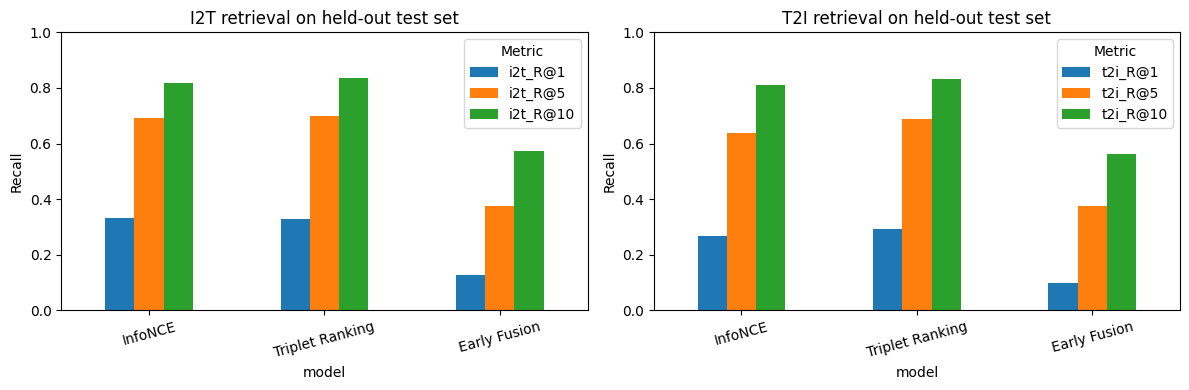

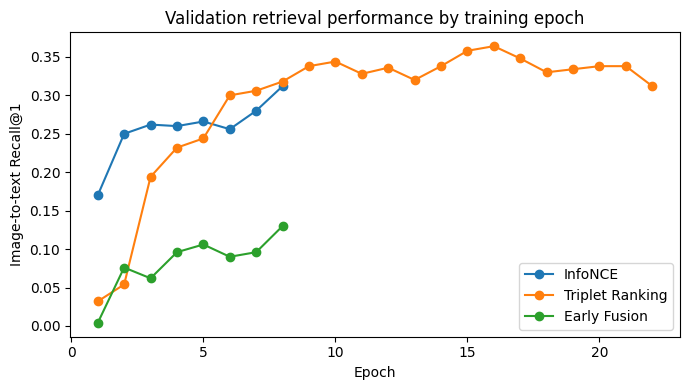

Note: validation curve alone cannot conclusively rule out overfitting; interpret alongside train loss and held-out test performance.


In [11]:
rows=[]
for name,scores in test_scores.items():
    rows.append({'model':name,**compute_metrics(scores,'test'),
                 'train_seconds':train_seconds[name],
                 'test_scoring_seconds':score_seconds[name],
                 'trainable_parameters':sum(p.numel() for p in models[name].parameters() if p.requires_grad)})
results=pd.DataFrame(rows).set_index('model')
display(results.round(4))
results.to_csv(OUT/'test_metrics.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,direction in zip(axes,('i2t','t2i')):
    subset=results[[f'{direction}_R@{k}' for k in (1,5,10)]]
    subset.plot.bar(ax=ax,rot=15)
    ax.set(title=f'{direction.upper()} retrieval on held-out test set',ylabel='Recall',ylim=(0,1))
    ax.legend(title='Metric')
plt.tight_layout();plt.savefig(OUT/'retrieval_comparison.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(7,4))
for name,h in histories.items(): ax.plot(h['epoch'],h['val_i2t_R@1'],marker='o',label=name)
ax.set(title='Validation retrieval performance by training epoch',xlabel='Epoch',ylabel='Image-to-text Recall@1')
ax.legend();plt.tight_layout();plt.savefig(OUT/'validation_curves.png',dpi=180);plt.show()
print('Note: validation curve alone cannot conclusively rule out overfitting; interpret alongside train loss and held-out test performance.')

## 9 — Error analysis and uncertainty

Inspect retrieval failures by ID and caption. Since images are absent from this feature-only ZIP, first retrieve image files separately before claiming visual interpretations. Bootstrap uncertainty is calculated at the **query level**, keeping the test scores fixed; it does not reflect variation across random training seeds.

In [12]:
for name,sc in test_scores.items():
    ri,rt=ranks_from_scores(sc,'test')
    errors=np.argsort(-ri)[:5]
    examples=[]
    for row in errors:
        image_idx=int(image_ix['test'][row]); best_col=int(sc[row].argmax())
        predicted_caption=captions[int(cap_ix['test'][best_col])]
        examples.append({'image_id':image_ids[image_idx],'correct_captions':image_to_caps[image_idx][:2],
                         'best_caption_prediction':predicted_caption,'first_relevant_rank':int(ri[row])})
    print('\n',name,'— difficult image queries')
    display(pd.DataFrame(examples).drop(columns='correct_captions'))

rng=np.random.default_rng(SEED)
boot=[]
for name,sc in test_scores.items():
    ri,rt=ranks_from_scores(sc,'test')
    for direction,r in [('i2t',ri),('t2i',rt)]:
        samples=rng.choice((r<=1).astype(float),size=(1000,len(r)),replace=True).mean(axis=1)
        boot.append({'model':name,'direction':direction,'R@1':np.mean(r<=1),
                     'bootstrap_CI_low':np.quantile(samples,.025),'bootstrap_CI_high':np.quantile(samples,.975)})
ci=pd.DataFrame(boot);display(ci.round(4));ci.to_csv(OUT/'bootstrap_ci.csv',index=False)


 InfoNCE — difficult image queries


,image_id,best_caption_prediction,first_relevant_rank
0,180920,a man standing on the bed while playing a guitar,443
1,413288,The bikes are all parked beside the sign.,387
2,682465,An airplane is at an airport with yellow hoses...,296
3,127612,A man is working on some parade floats.,220
4,486392,A man that is standing with a cow.,176



 Triplet Ranking — difficult image queries


,image_id,best_caption_prediction,first_relevant_rank
0,413288,The upturned skateboard is below a floating pa...,411
1,180920,"A man relaxing at home, watching television wi...",258
2,486392,a couple of people that are walking in some grass,212
3,682465,A flooded street with just the top of a parkin...,204
4,134369,A couple equipped with umbrella hats taking a ...,145



 Early Fusion — difficult image queries


,image_id,best_caption_prediction,first_relevant_rank
0,569828,Group of people standing around computer monit...,438
1,434987,Several bovine look out over the hills on a cl...,408
2,447196,A colorful train sits on the tracks in the sun...,355
3,740126,A young child and cat in a living room.,296
4,666749,Male skateboarder utilizing cemented curved aq...,225


,model,direction,R@1,bootstrap_CI_low,bootstrap_CI_high
0,InfoNCE,i2t,0.3340,0.2940,0.3780
1,InfoNCE,t2i,0.2689,0.2517,0.2849
2,Triplet Ranking,i2t,0.3300,0.2900,0.3700
3,Triplet Ranking,t2i,0.2928,0.2753,0.3112
4,Early Fusion,i2t,0.1280,0.1000,0.1580
5,Early Fusion,t2i,0.0995,0.0887,0.1115


## 10 — Interpretation, Limitations, Ethics and Reporting Checklist

### 10.1 Interpretation of Results

Three multimodal retrieval approaches—InfoNCE Contrastive Learning, Triplet Ranking, and Early Fusion—were independently implemented and evaluated on the same held-out COCO test set containing 500 images and 2,503 captions.

| Model | I2T R@1 | I2T R@5 | I2T R@10 | I2T MRR | T2I R@1 | T2I R@5 | T2I R@10 | T2I MRR |
|---|---:|---:|---:|---:|---:|---:|---:|---:|
| InfoNCE | 33.40% | 69.20% | 81.80% | 0.4889 | 26.89% | 63.76% | 81.14% | 0.4337 |
| Triplet Ranking | 33.00% | 70.00% | 83.60% | 0.4920 | 29.28% | 68.68% | 83.30% | 0.4611 |
| Early Fusion | 12.80% | 37.60% | 57.20% | 0.2557 | 9.95% | 37.63% | 56.17% | 0.2390 |

**Key findings:**

- **Triplet Ranking achieved the strongest overall retrieval performance**, leading in seven of eight reported metrics, including Text-to-Image Recall@1 (29.28%) and MRR (0.4611). Its top-k negative-mining strategy improved the learning of discriminative image–caption relationships.
- **InfoNCE achieved the highest Image-to-Text Recall@1 (33.40%)**, marginally exceeding Triplet Ranking (33.00%). It provided competitive retrieval performance using a symmetric contrastive objective.
- **Early Fusion performed substantially worse** in both retrieval directions. Its binary matching classifier must evaluate candidate image–caption combinations individually, while the dual-encoder approaches learn directly comparable representations.
- Performance improved considerably between Recall@1 and Recall@10 for all three approaches. This suggests that relevant matches frequently appeared among the leading candidates even when the top-ranked prediction was incorrect.

Overall, the experiments suggest that learning a coordinated cross-modal embedding space is more effective for this retrieval setting than the implemented pairwise early-fusion classifier.

### 10.2 Computational Efficiency

| Model | Training Time | Test Scoring Time | Trainable Parameters |
|---|---:|---:|---:|
| InfoNCE | 10.68 s | 0.072 s | 1,705,472 |
| Triplet Ranking | 29.50 s | 0.073 s | 1,705,472 |
| Early Fusion | 98.95 s | 10.534 s | 918,529 |

All recorded experiments ran on CPU using precomputed visual and textual features.

InfoNCE was the fastest to train. Triplet Ranking required additional epochs and negative-mining operations but achieved stronger performance on most retrieval metrics.

Early Fusion required approximately 144 times as much test-scoring time as InfoNCE. Despite having fewer trainable parameters, its pairwise scoring architecture resulted in substantially higher computational cost.

These measurements exclude the original ResNet-50 and BERT feature-extraction costs. Therefore, they represent the downstream training and retrieval stages rather than complete end-to-end system latency.

### 10.3 Overfitting Assessment

Training losses decreased across all three approaches, demonstrating that the models learned from the training data.

For Triplet Ranking, validation performance improved substantially during the initial epochs and reached its best combined Recall@1 at epoch 16. Although training loss continued decreasing, validation performance fluctuated afterwards. Early stopping selected epoch 16, limiting further training without consistent validation improvement.

InfoNCE showed generally improving validation retrieval performance across its eight training epochs. Early Fusion also improved, although its validation results fluctuated.

These observations suggest possible overfitting or diminishing generalisation benefits during later Triplet Ranking training. However, training loss and validation retrieval metrics measure different quantities, so the curves alone do not establish the exact degree of overfitting.

### 10.4 Error Analysis

Retrieval failures were inspected by identifying queries where the first correct caption appeared far down the ranked list.

For example, certain image queries had their first relevant caption ranked beyond position 200, indicating substantial confusion between semantically related or visually similar content.

Potential contributing factors include:

- Captions describing only selected objects or activities within complex images.
- Similar visual scenes corresponding to different textual descriptions.
- Ambiguous language and multiple valid descriptions of the same image.
- Limitations of fixed pretrained features when capturing fine-grained visual relationships.

These are plausible explanations rather than confirmed causes for individual failures. Direct inspection of the original images would be required to validate them.

### 10.5 Statistical Uncertainty

Query-level bootstrap confidence intervals were calculated using 1,000 resamples.

For Image-to-Text Recall@1:

- InfoNCE: 33.40%, 95% CI [29.40%, 37.80%].
- Triplet Ranking: 33.00%, 95% CI [29.00%, 37.00%].
- Early Fusion: 12.80%, 95% CI [10.00%, 15.80%].

The considerable overlap between the InfoNCE and Triplet Ranking intervals indicates uncertainty around their relative Image-to-Text performance. These individual intervals do not constitute a formal paired significance test.

The intervals capture query-sampling uncertainty for the trained models, but not variability from different random seeds, model initialisations or training runs.

### 10.6 Limitations

1. **Pretrained feature dependency:** ResNet-50 and BERT were used as frozen feature extractors, limiting adaptation to the retrieval task.
2. **Dataset generalisation:** Experiments used a fixed subset of COCO 2017 images and captions, limiting conclusions about performance on unfamiliar domains.
3. **Limited training diversity:** The study used 4,000 training images and their associated captions.
4. **Single-seed evaluation:** Results may vary across random initialisations and repeated training runs.
5. **Encoder mismatch:** Independently pretrained image and text encoders may not preserve equivalent semantic information.
6. **Computational considerations:** Early Fusion requires pairwise candidate scoring, increasing retrieval costs as the candidate collection grows.

### 10.7 Ethics and Bias Assessment

Image–caption datasets may contain representational imbalances involving cultural settings, geographic regions, occupations and demographic groups.

Models trained on such data may reproduce stereotypical associations, overlook underrepresented visual concepts or retrieve inappropriate captions for certain subjects.

**Potential mitigation strategies** include evaluating performance across well-defined demographic and contextual subsets, expanding representative training data, reviewing harmful retrieval errors and documenting limitations transparently.

These measures have not been experimentally verified in the present study. Consequently, no claim of demonstrated demographic fairness can be made.

Deployment would additionally require privacy safeguards, appropriate handling of image rights, human oversight for sensitive applications and testing on data representative of the intended users.

### 10.8 Recommendations and Future Work

Future improvements should include:

- Fine-tuning image and text encoders jointly rather than relying exclusively on frozen representations.
- Evaluating more sophisticated negative-mining strategies and attention-based fusion.
- Performing repeated experiments using multiple random seeds.
- Measuring end-to-end inference latency, including feature extraction.
- Comparing the trained approaches against a pretrained CLIP reference model.
- Conducting more detailed, image-supported error analysis and subgroup bias evaluations.

**Conclusion:** Triplet Ranking provided the strongest overall retrieval performance, while InfoNCE offered an attractive balance between accuracy and computational efficiency. The significantly slower and less accurate Early Fusion implementation illustrates the importance of architecture selection for scalable multimodal retrieval. Further cross-domain evaluation and repeated training experiments are required before generalising these findings.

### References (verify citation formatting)
1. Lin, T.-Y. et al. (2014). *Microsoft COCO: Common Objects in Context*. ECCV. https://arxiv.org/abs/1405.0312
2. He, K. et al. (2016). *Deep Residual Learning for Image Recognition*. CVPR. https://arxiv.org/abs/1512.03385
3. Devlin, J. et al. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL. https://arxiv.org/abs/1810.04805
4. van den Oord, A., Li, Y. and Vinyals, O. (2018). *Representation Learning with Contrastive Predictive Coding*. https://arxiv.org/abs/1807.03748
5. Radford, A. et al. (2021). *Learning Transferable Visual Models From Natural Language Supervision*. ICML. https://arxiv.org/abs/2103.00020
6. Schroff, F., Kalenichenko, D. and Philbin, J. (2015). *FaceNet: A Unified Embedding for Face Recognition and Clustering*. CVPR. https://arxiv.org/abs/1503.03832